## Chủ đề số 14: Bank marketing
## Bài toán: Dự đoán khách hàng có đăng ký gửi tiền kỳ hạn hay không (Yes/No) 
## Loại bài toán: Classification

### Tập dữ liệu: UCI Bank Marketing (https://archive.ics.uci.edu/dataset/222/bank+marketing)
### Sử dụng 4 thuật toán: Logistic Regression, KNN, Decision Tree, RandomForest
### Độ đo: F1, Recall, ROC-AUC

### 1. Đọc dữ liệu

In [3]:
import pandas as pd

df = pd.read_csv("data/bank-additional.csv", sep=";")
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,30,blue-collar,married,basic.9y,no,yes,no,cellular,may,fri,...,2,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
1,39,services,single,high.school,no,no,no,telephone,may,fri,...,4,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
2,25,services,married,high.school,no,yes,no,telephone,jun,wed,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.962,5228.1,no
3,38,services,married,basic.9y,no,unknown,unknown,telephone,jun,fri,...,3,999,0,nonexistent,1.4,94.465,-41.8,4.959,5228.1,no
4,47,admin.,married,university.degree,no,yes,no,cellular,nov,mon,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.191,5195.8,no


### 2. EDA

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Đọc dữ liệu
df = pd.read_csv(
    "data/bank-additional-full.csv",
    sep=";"
)

# Hiển thị 5 dòng đầu tiên
display(df.head())

# Kích thước dữ liệu
print("Số dòng:", df.shape[0])
print("Số cột:", df.shape[1])

# Thông tin dữ liệu
df.info()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


Số dòng: 41188
Số cột: 21
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   

y
no     36548
yes     4640
Name: count, dtype: int64
y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64


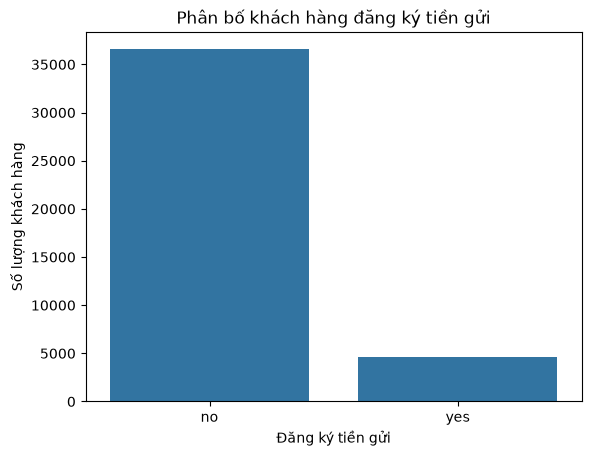

In [9]:
print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True) * 100)

sns.countplot(data=df, x="y")
plt.title("Phân bố khách hàng đăng ký tiền gửi")
plt.xlabel("Đăng ký tiền gửi")
plt.ylabel("Số lượng khách hàng")
plt.show()

### 3. Tiền xử lý dữ liệu

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Giữ "unknown" như một nhóm riêng; loại bản ghi trùng và thiếu nhãn.
df_model = df.drop_duplicates().dropna(subset=["y"]).copy()

# duration chỉ biết sau cuộc gọi, không dùng để dự đoán trước cuộc gọi.
X = df_model.drop(columns=["y", "duration"])
y = df_model["y"].map({"no": 0, "yes": 1})

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ]
)

# Chỉ fit trên train để tránh rò rỉ thông tin từ tập test.
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)
feature_names = preprocessor.get_feature_names_out()

print(f"Số dòng sau khi loại trùng/thiếu nhãn: {len(df_model)}")
print(f"Số đặc trưng sau mã hóa: {len(feature_names)}")
print(f"Train: X={X_train.shape}, y={y_train.shape}")
print(f"Test:  X={X_test.shape}, y={y_test.shape}")
print("Tỷ lệ nhãn trong train (%):")
print(y_train.map({0: "no", 1: "yes"}).value_counts(normalize=True).mul(100).round(2))

Số dòng sau khi loại trùng/thiếu nhãn: 4119
Số đặc trưng sau mã hóa: 62
Train: X=(3295, 62), y=(3295,)
Test:  X=(824, 62), y=(824,)
Tỷ lệ nhãn trong train (%):
y
no     89.04
yes    10.96
Name: proportion, dtype: float64


### 4. Thuật toán Logistic Regression

### 5. Thuật toán KNN

### 6. Thuật toán Decision Tree

### 7. Thuật toán RandomForest

### 8. So sánh kết quả các mô hình 
